STEP 1 | Data source : REAL — UCI German Credit (OpenML)
        Dataset shape: (1000, 51)
        Missing values: 0
   duration  credit_amount  installment_commitment  residence_since  age  \
0         6           1169                       4                4   67   
1        48           5951                       2                2   22   
2        12           2096                       2                3   49   
3        42           7882                       2                4   45   
4        24           4870                       3                4   53   

   existing_credits  num_dependents  
0                 2               1  
1                 1               1  
2                 1               2  
3                 1               2  
4                 2               2  

Class balance (1 = good / 0 = risky):
creditworthy
1    0.7
0    0.3
Name: proportion, dtype: float64 

STEP 2 | Train rows: 800  |  Test rows: 200

--- Logistic Regression ---  (CV AUC 0.7788 +/- 

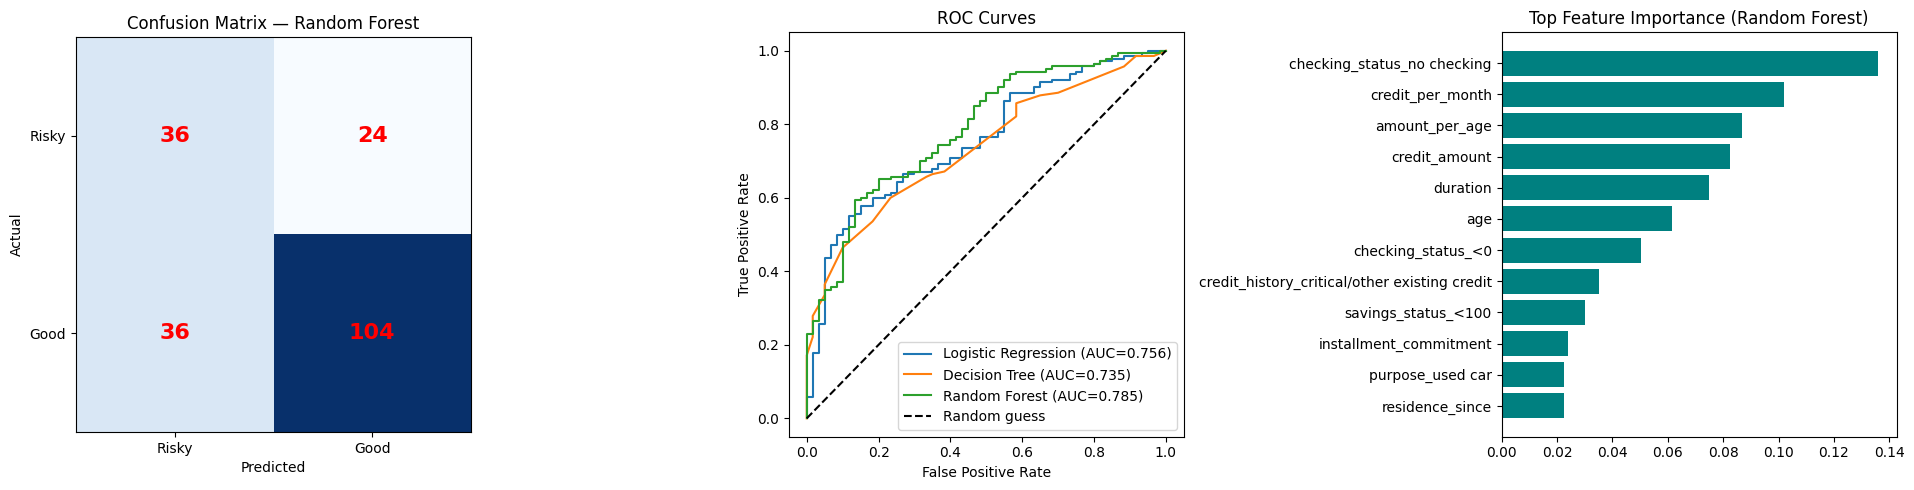

STEP 5 | Plot saved -> task1_credit_scoring_results.png

STEP 6 | NEW APPLICANT DECISION
  Prediction  : CREDITWORTHY - approve
  Confidence  : 70.05% chance of repaying
  Actual label: Creditworthy


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             classification_report, confusion_matrix)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def load_real_credit_data():
    """UCI German Credit (credit-g) from OpenML — needs internet ON."""
    from sklearn.datasets import fetch_openml
    raw = fetch_openml("credit-g", version=1, as_frame=True).frame

    y = (raw["class"] == "good").astype(int) 
    X = raw.drop(columns="class")

    X["credit_per_month"] = (X["credit_amount"] / X["duration"]).round(2)
    X["amount_per_age"]   = (X["credit_amount"] / X["age"]).round(2)

    X = pd.get_dummies(X, drop_first=True)
    X[X.select_dtypes("bool").columns] = X.select_dtypes("bool").astype(int)

    df = X.copy()
    df["creditworthy"] = y.values
    return df


def build_credit_dataset(n=5000):
    """Backup: realistic synthetic financial data (used only if offline)."""
    age             = np.random.randint(21, 65, n)
    income          = np.random.lognormal(10.6, 0.45, n).round(0)
    employment_yrs  = np.clip(np.random.gamma(2.2, 2.5, n), 0, age - 18).round(1)
    debt            = (income * np.random.beta(2, 5, n) * 2.2).round(0)
    num_loans       = np.random.poisson(1.6, n)
    late_payments   = np.random.poisson(1.1, n)
    credit_util     = np.random.beta(2, 4, n).round(3)
    credit_hist_yrs = np.clip(np.random.normal(8, 4, n), 0.5, 40).round(1)

    hidden_stability = np.random.normal(0, 1, n)
    hidden_savings   = np.random.beta(2, 3, n)

    risk = (2.2 * (debt / income)
            + 0.45 * late_payments
            + 1.6 * credit_util
            - 0.09 * employment_yrs
            - 0.05 * credit_hist_yrs
            + 0.18 * num_loans
            - 0.60 * hidden_stability
            - 0.80 * hidden_savings
            - 2.00)
    risk += np.random.normal(0, 0.35, n)                     
    prob_default = 1 / (1 + np.exp(-2.0 * risk))            
    default = (np.random.rand(n) < prob_default).astype(int)

    return pd.DataFrame({
        "age": age,
        "annual_income": income,
        "employment_years": employment_yrs,
        "total_debt": debt,
        "num_loans": num_loans,
        "late_payments_2y": late_payments,
        "credit_utilization": credit_util,
        "credit_history_years": credit_hist_yrs,
        "debt_to_income": (debt / income).round(3),               
        "income_per_loan": (income / (num_loans + 1)).round(0),   
        "creditworthy": 1 - default                              
    })


try:
    df = load_real_credit_data()
    DATA_SOURCE = "REAL — UCI German Credit (OpenML)"
except Exception as e:
    print(f"Real data unavailable ({type(e).__name__}) — using synthetic data.\n")
    df = build_credit_dataset()
    DATA_SOURCE = "SYNTHETIC — generated inside this notebook"

print("STEP 1 | Data source :", DATA_SOURCE)
print("        Dataset shape:", df.shape)
print("        Missing values:", int(df.isna().sum().sum()))
print(df.iloc[:, :7].head())
print("\nClass balance (1 = good / 0 = risky):")
print(df["creditworthy"].value_counts(normalize=True).round(3), "\n")


X = df.drop(columns="creditworthy")
y = df["creditworthy"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"STEP 2 | Train rows: {len(X_train)}  |  Test rows: {len(X_test)}\n")


models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                   random_state=RANDOM_STATE))]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=20, class_weight="balanced",
        random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=5,
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, roc_data = [], {}

for name, model in models.items():
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")

    model.fit(X_train, y_train)
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]     

    results.append({
        "Model":      name,
        "CV ROC-AUC": cv_auc.mean(),
        "Accuracy":   accuracy_score(y_test, y_pred),
        "Precision":  precision_score(y_test, y_pred),
        "Recall":     recall_score(y_test, y_pred),
        "F1-Score":   f1_score(y_test, y_pred),
        "ROC-AUC":    roc_auc_score(y_test, y_proba),
    })
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_data[name] = (fpr, tpr, roc_auc_score(y_test, y_proba))

    print(f"--- {name} ---  (CV AUC {cv_auc.mean():.4f} +/- {cv_auc.std():.4f})")
    print(classification_report(y_test, y_pred,
                                target_names=["Risky (0)", "Creditworthy (1)"]))

scores = pd.DataFrame(results).set_index("Model").round(4)
print("STEP 4 | MODEL COMPARISON")
print(scores, "\n")

best_name  = scores["ROC-AUC"].idxmax()
best_model = models[best_name]
print(f"BEST MODEL by ROC-AUC: {best_name}\n")


fig, axes = plt.subplots(1, 3, figsize=(19, 5))

cm = confusion_matrix(y_test, best_model.predict(X_test))
axes[0].imshow(cm, cmap="Blues")
axes[0].set_title(f"Confusion Matrix — {best_name}")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Risky", "Good"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["Risky", "Good"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center",
                     color="red", fontsize=16, fontweight="bold")

for name, (fpr, tpr, auc) in roc_data.items():
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curves"); axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate"); axes[1].legend(loc="lower right")

rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(12).sort_values()
axes[2].barh(imp.index, imp.values, color="teal")
axes[2].set_title("Top Feature Importance (Random Forest)")

plt.tight_layout()
plt.savefig("task1_credit_scoring_results.png", dpi=120, bbox_inches="tight")
plt.show()
print("STEP 5 | Plot saved -> task1_credit_scoring_results.png\n")

new_applicant = X_test.iloc[[0]]
pred  = best_model.predict(new_applicant)[0]
proba = best_model.predict_proba(new_applicant)[0][1]

print("STEP 6 | NEW APPLICANT DECISION")
print(f"  Prediction  : {'CREDITWORTHY - approve' if pred == 1 else 'RISKY - reject'}")
print(f"  Confidence  : {proba:.2%} chance of repaying")
print(f"  Actual label: {'Creditworthy' if y_test.iloc[0] == 1 else 'Risky'}")